# CCD Image Processing and Photometry
### An Analysis of Messier 1 Using Astronomical Imaging Data

**Danessa Ruff**  
Michigan State University | Astrophysics  
*Independent extension of AST 208 coursework*

---

## Overview

In AST 208, I worked with astronomical CCD images and learned how bias, dark current, and flat-field corrections affect image quality.

I wanted to build on that work by looking more closely at the calibration process and how it affects photometric measurements.

For this project, I used images of Messier 1 taken through B, V, and r filters. I applied the calibration corrections, compared the resulting images, and used aperture photometry to measure stellar brightness.

## Research Question

How does CCD calibration affect image quality and the measurement of stellar brightness in astronomical observations?

In [59]:
# If these packages aren't installed, uncomment and run the line below.
# %pip install astropy pandas matplotlib

## 1. Imports and helper functions

In [31]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.origin"] = "lower"

def load_fits(path):
    with fits.open(path) as hdul:
        return hdul[0].data.astype(float), hdul[0].header

def robust_limits(image, low=5, high=99.5):
    return np.percentile(image, [low, high])

def show_image(image, title, cmap="gray", low=5, high=99.5, colorbar=True):
    vmin, vmax = np.percentile(image, [low, high])    
    plt.figure()
    plt.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.title(title)
    if colorbar:
        plt.colorbar(label="Counts")
    plt.tight_layout()
    plt.show()

def aperture_photometry(image, x0, y0, r_ap=7, r_in=10, r_out=16):
    yy, xx = np.indices(image.shape)
    rr = np.sqrt((xx - x0)**2 + (yy - y0)**2)
    ap_mask = rr <= r_ap
    bg_mask = (rr >= r_in) & (rr <= r_out)
    bg_median = np.median(image[bg_mask])
    net_flux = image[ap_mask].sum() - bg_median * ap_mask.sum()
    return {"net_flux": net_flux, "background_median": bg_median, "aperture_pixels": ap_mask.sum(),
            "background_pixels": bg_mask.sum(), "ap_mask": ap_mask, "bg_mask": bg_mask}

## 2. Loading the FITS Images

The Messier 1 images are stored in a ZIP archive containing the raw science frames, bias and dark frames, and flat-field images.

I extracted the files and located the FITS images needed for calibration.

In [32]:
zip_path = "Lab6_images (1).zip"
extract_root = "Lab6_images_extracted"

os.makedirs(extract_root, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_root)

fits_paths = {}
for folder, _, files in os.walk(extract_root):
    for file in files:
        if file.endswith(".fits") and not file.startswith("._"):
            fits_paths[file] = os.path.join(folder, file)

sorted(fits_paths.keys())

['Bflat.fits',
 'Vflat.fits',
 'bias.fits',
 'dark.fits',
 'm1_B_raw.fits',
 'm1_V_raw.fits',
 'm1_r_raw.fits',
 'rflat.fits']

## 3. Load the calibration frames and the raw science images

In [33]:
bias, bias_hdr = load_fits(fits_paths["bias.fits"])
dark, dark_hdr = load_fits(fits_paths["dark.fits"])

frames = {}
for band, raw_name, flat_name in [("B", "m1_B_raw.fits", "Bflat.fits"), ("V", "m1_V_raw.fits", "Vflat.fits"), ("R", "m1_r_raw.fits", "rflat.fits"),]:
    raw, raw_hdr = load_fits(fits_paths[raw_name])
    flat, flat_hdr = load_fits(fits_paths[flat_name])
    frames[band] = {"raw": raw, "raw_hdr": raw_hdr, "flat": flat, "flat_hdr": flat_hdr,}

summary_rows = []

for band, frame in frames.items():
    raw_hdr = frame["raw_hdr"]
    flat_hdr = frame["flat_hdr"]
    
    summary_rows.append({"band": band, "raw_exptime_s": raw_hdr.get("EXPTIME"), "raw_filter": raw_hdr.get("FILTER"),
                         "flat_exptime_s": flat_hdr.get("EXPTIME"), "flat_filter": flat_hdr.get("FILTER"),})

pd.DataFrame(summary_rows)

,band,raw_exptime_s,raw_filter,flat_exptime_s,flat_filter
0,B,54.9,B,24.370733,B
1,V,36.6,V,3.779278,V
2,R,36.6,rprime,6.843950,rprime


## 4. CCD calibration

The dark frame supplied with the lab data already has the bias removed, while the flats already have both bias and dark corrections applied.  
For each science frame, the calibrated image is computed as:

`science_calibrated = (science_raw - bias - dark_scaled) / flat_normalized`

where

`dark_scaled = dark * (science_exptime / dark_exptime)`

and

`flat_normalized = flat / mean(flat)`


In [36]:
for band in frames:
    raw = frames[band]["raw"]
    flat = frames[band]["flat"]
    exptime = frames[band]["raw_hdr"]["EXPTIME"]

    dark_scaled = dark * exptime / dark_hdr["EXPTIME"]
    flat_norm = flat / np.mean(flat)

    if not np.all(np.isfinite(flat_norm)) or np.any(flat_norm <= 0):
        raise ValueError(f"Invalid flat field: {band}")

    frames[band]["calibrated"] = (raw - bias - dark_scaled) / flat_norm
    frames[band]["dark_scaled"] = dark_scaled
    frames[band]["flat_norm"] = flat_norm

calibration_stats = []

for band in frames:
    raw = frames[band]["raw"]
    calibrated = frames[band]["calibrated"]
    calibration_stats.append({"band": band, "raw_mean": np.mean(raw), "calibrated_mean": np.mean(calibrated),
        "calibrated_min": np.min(calibrated), "calibrated_max": np.max(calibrated)})
pd.DataFrame(calibration_stats)

,band,raw_mean,calibrated_mean,calibrated_min,calibrated_max
0,B,2112.634563,317.685355,-2436.789552,7151.224656
1,V,2119.419730,328.102373,-1683.988131,6127.464944
2,R,2189.025854,397.671067,-1634.617189,6021.816563


## 5. Visualize the Raw and Calibrated Images

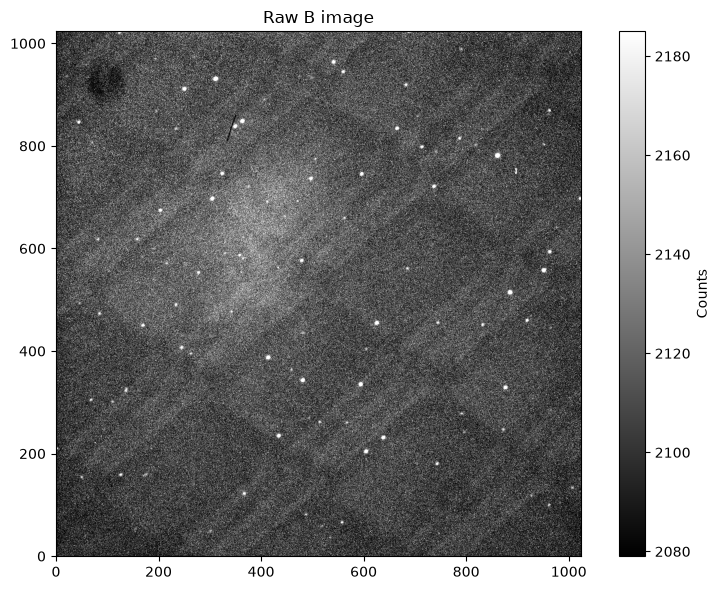

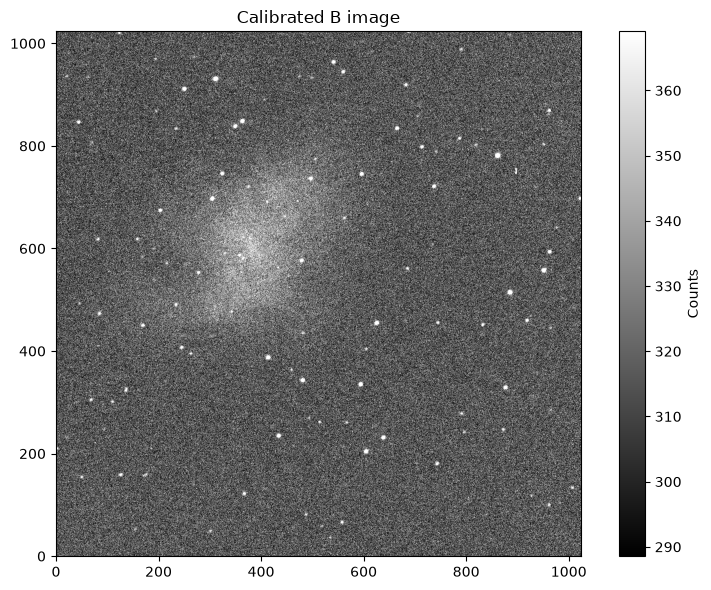

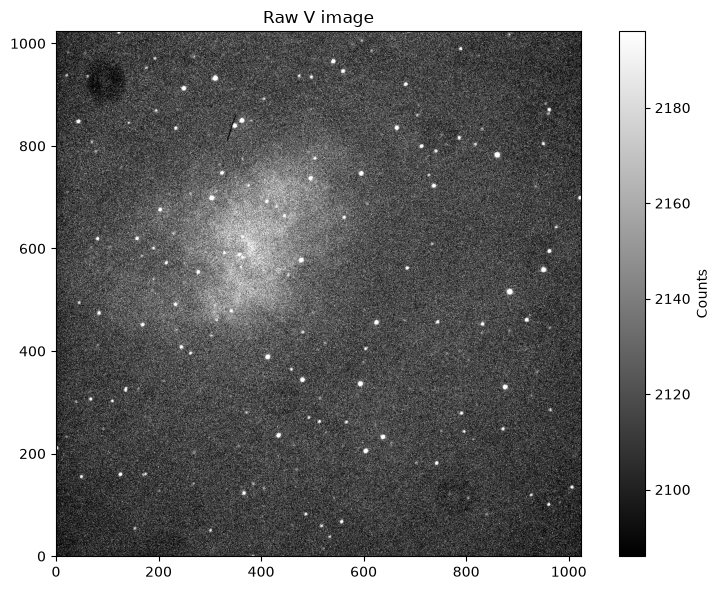

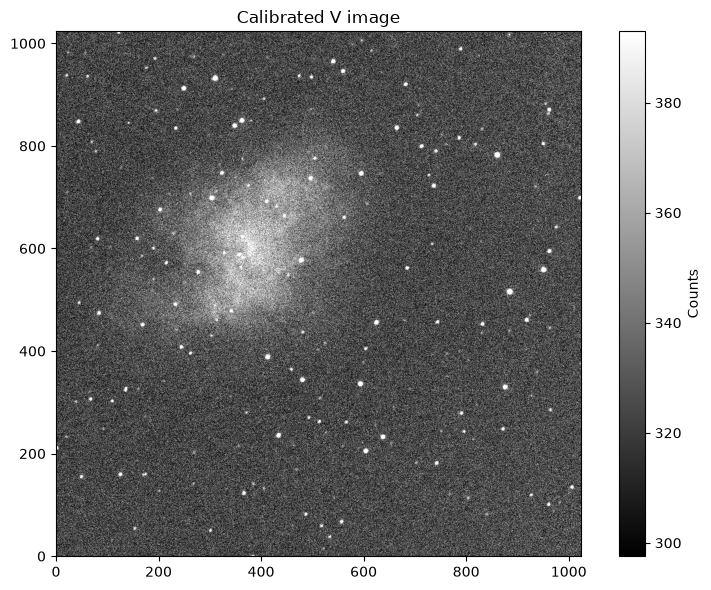

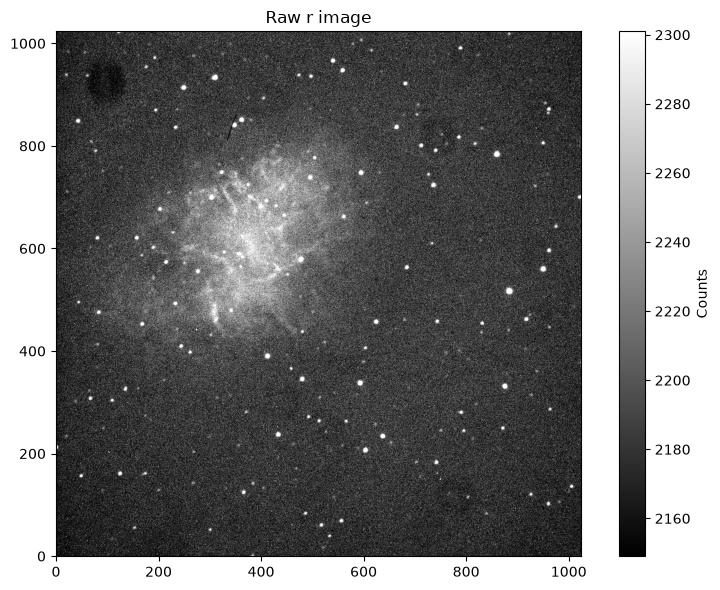

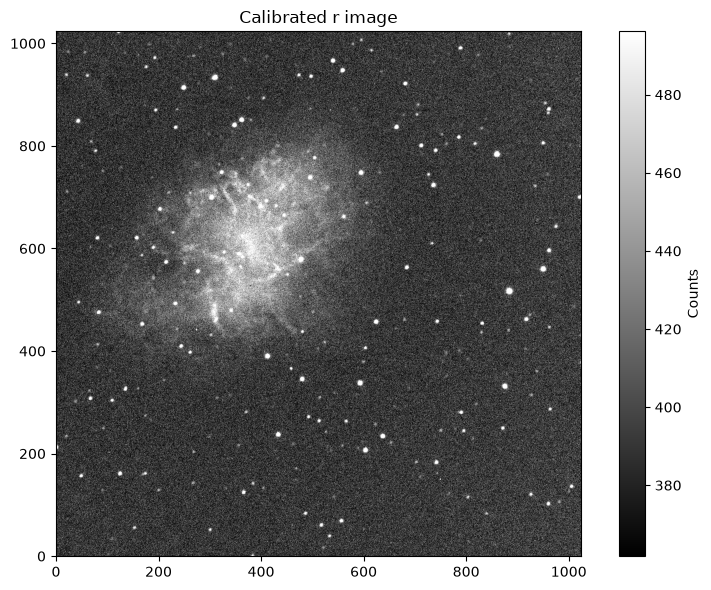

In [19]:
show_image(frames["B"]["raw"], "Raw B image")
show_image(frames["B"]["calibrated"], "Calibrated B image")

show_image(frames["V"]["raw"], "Raw V image")
show_image(frames["V"]["calibrated"], "Calibrated V image")

show_image(frames["R"]["raw"], "Raw r image")
show_image(frames["R"]["calibrated"], "Calibrated r image")

## 6. Create a Three-Color Composite Image

The calibrated r, V, and B images are assigned to the red, green, and blue channels, respectively. Each channel is independently normalized for visualization, so the resulting composite is not a photometrically calibrated true-color image.

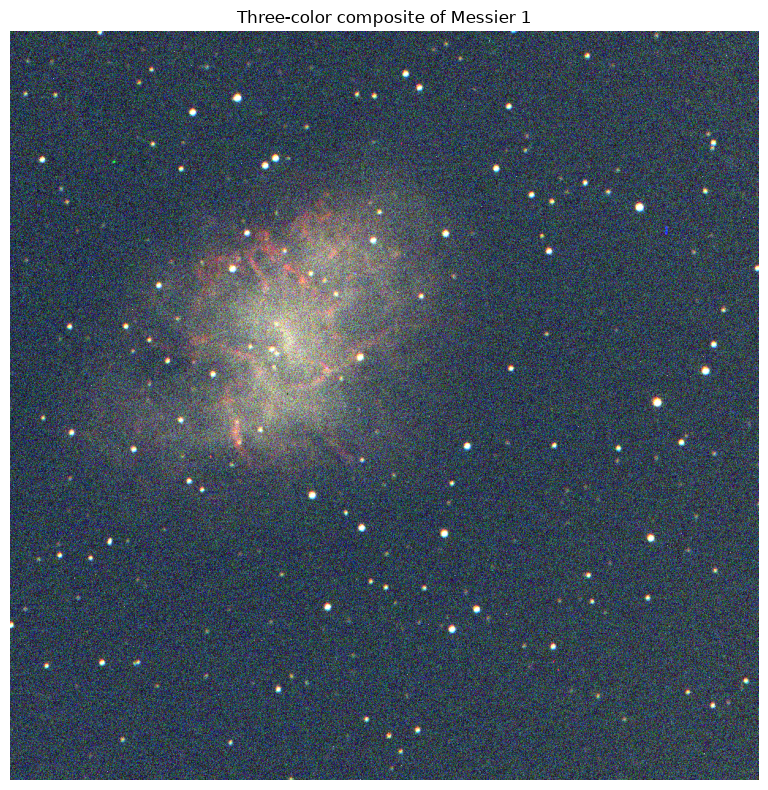

In [41]:
def normalize_for_rgb(image):
    p1, p99 = np.percentile(image, [5, 99.7])
    scaled = (image - p1) / max(p99 - p1, 1e-10)
    return np.clip(scaled, 0, 1)

rgb = np.dstack([normalize_for_rgb(frames["R"]["calibrated"]), normalize_for_rgb(frames["V"]["calibrated"]), normalize_for_rgb(frames["B"]["calibrated"]),])

plt.figure(figsize=(8, 8))
plt.imshow(rgb)
plt.title("Three-color composite of Messier 1")
plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Aperture Photometry on a Bright Common Source

To keep the procedure reproducible, the notebook automatically finds a bright point source that is strong in all three calibrated frames.  
The source position is selected from the product of the normalized B, V, and R images, which favors stars that are bright in every band rather than single-band outliers.
I visually inspected the automatically selected source to confirm that it was a star before performing aperture photometry.

In [42]:
score = np.ones_like(frames["B"]["calibrated"])
for band in ["B", "V", "R"]:
    img = frames[band]["calibrated"]
    p1, p99 = np.percentile(img, [5, 99.9])
    score *= np.clip((img - p1) / max(p99 - p1, 1e-10), 0, None)

#ignore the outer 80 pixels to avoid false detections at the edges
score[:80, :] = 0
score[-80:, :] = 0
score[:, :80] = 0
score[:, -80:] = 0

y_star, x_star = np.unravel_index(np.argmax(score), score.shape)
x_star, y_star

(530, 666)

In [44]:
photometry_rows = []
ap_results = {}

for band in ["B", "V", "R"]:
    result = aperture_photometry(frames[band]["calibrated"], x_star, y_star, r_ap=7, r_in=10, r_out=16)
    ap_results[band] = result
    photometry_rows.append({"band": band, "net_flux": result["net_flux"], "background_median": result["background_median"],
        "aperture_pixels": result["aperture_pixels"], "background_pixels": result["background_pixels"],})

photometry_df = pd.DataFrame(photometry_rows)
photometry_df

,band,net_flux,background_median,aperture_pixels,background_pixels
0,B,5742.895804,324.577482,149,492
1,V,3910.712318,342.361681,149,492
2,R,3890.388558,424.017801,149,492


### Effect of Calibration on Aperture Photometry

I compared the measured flux of the same source before and after calibration in each filter.

I used the same aperture and background annulus for both measurements to see how the calibration process changed the resulting flux values.

In [46]:
comparison_rows = []

for band in ["B", "V", "R"]:
    raw_result = aperture_photometry(frames[band]["raw"], x_star, y_star, r_ap=7, r_in=10, r_out=16)
    calibrated_result = ap_results[band]

    comparison_rows.append({"Band": band, "Raw flux": raw_result["net_flux"], "Calibrated flux": calibrated_result["net_flux"],
        "Percent change": ((calibrated_result["net_flux"] - raw_result["net_flux"]) / raw_result["net_flux"] * 100
            if raw_result["net_flux"] != 0 else np.nan)})

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,Band,Raw flux,Calibrated flux,Percent change
0,B,10008.0,5742.895804,-42.616948
1,V,6651.0,3910.712318,-41.201138
2,R,6504.0,3890.388558,-40.184678


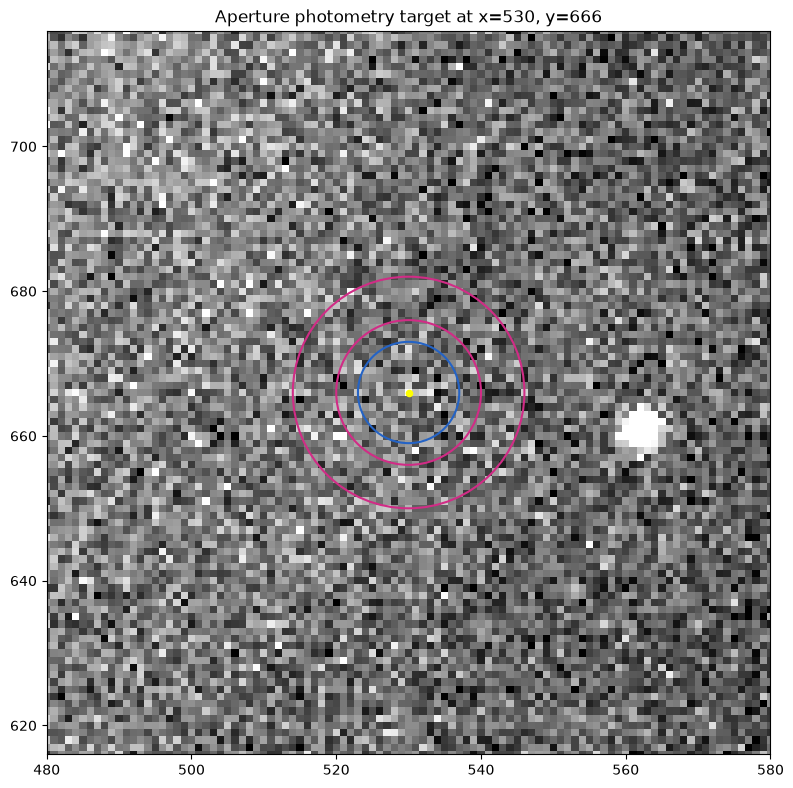

In [61]:
#plots chosen aperture on calibrated V image
img = frames["V"]["calibrated"]

yy, xx = np.indices(img.shape)
rr = np.sqrt((xx - x_star)**2 + (yy - y_star)**2)

plt.figure(figsize=(8, 8))
#vmin, vmax = robust_limits(img)
vmin, vmax = np.percentile(img, [5, 99.5])
plt.imshow(img, cmap="grey", vmin=vmin, vmax=vmax)
for radius, color in [(7, "#2463C5"), (10, "#D12C86"), (16, "#D12C86")]:
    circle = plt.Circle((x_star, y_star), radius, fill=False, color=color, linewidth=1.5)
    plt.gca().add_patch(circle)
plt.scatter([x_star], [y_star], color="yellow", s=20)
plt.title(f"Aperture photometry target at x={x_star}, y={y_star}")
plt.xlim(x_star - 50, x_star + 50)
plt.ylim(y_star - 50, y_star + 50)
plt.tight_layout()
plt.show()

### Instrumental color indices

From the aperture fluxes we can form simple instrumental color indices:

`B - V = -2.5 log10( F_B / F_V )`

`V - R = -2.5 log10( F_V / F_R )`

These are instrumental color indices calculated from the measured fluxes. They have not been corrected for differences in exposure time, photometric zero points, or atmospheric extinction, so they should not be interpreted as standard stellar colors.


In [55]:
F_B = ap_results["B"]["net_flux"]
F_V = ap_results["V"]["net_flux"]
F_R = ap_results["R"]["net_flux"]

B_minus_V = -2.5 * np.log10(F_B / F_V)
V_minus_R = -2.5 * np.log10(F_V / F_R)

pd.DataFrame({"quantity": ["B-V", "V-R"], "value_mag": [B_minus_V, V_minus_R]})

,quantity,value_mag
0,B-V,-0.417188
1,V-R,-0.005657


## 8. Results Summary

In [57]:
results_table = pd.DataFrame([
    {"result": "Bright source x pixel", "value": x_star, "units": "pixel"},
    {"result": "Bright source y pixel", "value": y_star, "units": "pixel"},
    {"result": "Aperture flux in B", "value": ap_results["B"]["net_flux"], "units": "counts"},
    {"result": "Aperture flux in V", "value": ap_results["V"]["net_flux"], "units": "counts"},
    {"result": "Aperture flux in R", "value": ap_results["R"]["net_flux"], "units": "counts"},
    {"result": "Instrumental B-V", "value": B_minus_V, "units": "mag"},
    {"result": "Instrumental V-R", "value": V_minus_R, "units": "mag"},])
results_table

,result,value,units
0,Bright source x pixel,530.000000,pixel
1,Bright source y pixel,666.000000,pixel
2,Aperture flux in B,5742.895804,counts
3,Aperture flux in V,3910.712318,counts
4,Aperture flux in R,3890.388558,counts
5,Instrumental B-V,-0.417188,mag
6,Instrumental V-R,-0.005657,mag


## Results and Discussion

The calibration process changed the pixel values in all three Messier 1 images. Bias and dark subtraction removed instrumental contributions, while flat-field correction accounted for differences in pixel sensitivity.

The calibrated B, V, and r images were combined into a three-color composite, allowing the nebula and surrounding stars to be viewed across different filters.

I identified and visually verified a bright star in the images and measured its flux using aperture photometry. Comparing the raw and calibrated measurements showed how CCD calibration affected the measured flux in each filter.

I also calculated instrumental B−V and V−r color indices.


## Limitations and Future Work

The instrumental color indices have not been corrected for exposure time, photometric zero points, or atmospheric extinction, so they cannot be interpreted as standard stellar colors.

The photometry also depends on the selected aperture and background region, which may affect the measured flux.

Future improvements could include estimating photometric uncertainties, testing different aperture sizes, and calibrating the measurements against reference stars.


## Conclusion

This project extended my AST 208 coursework by combining CCD calibration with automated source selection and aperture photometry of Messier 1 observations.

The analysis demonstrated how calibration changes measured flux and how multi-filter observations can be used to obtain instrumental color measurements.

---
## Credits & Acknowledgments

**Data Source:** Messier 1 (Crab Nebula) CCD observations obtained through the Skynet Robotic Telescope Network using the PROMPT 5 telescope at Cerro Tololo, Chile, as identified in AST 208 Lab 5.

**Data Provided By:** Dr. Joey Rodriguez, Michigan State University, through AST 208 coursework.

**Academic Background:** This project builds on AST 208 Labs 5–7, which introduced CCD calibration, three-color astronomical imaging, and aperture photometry.

**Independent Investigation:** I extended the original coursework by implementing an automated source-selection method, applying aperture photometry to the Messier 1 images, comparing raw and calibrated flux measurements, and calculating instrumental color indices across the B, V, and r filters.